# Exploración reproducible: `spanish_phishing`

Este notebook lee el CSV original sin modificarlo. El análisis completo se guarda en [`../reports/spanish_phishing.md`](../reports/spanish_phishing.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
while not (HERE / 'notebooks' / 'exploracion-datasets' / 'dataset_audit.py').exists():
    if HERE.parent == HERE:
        raise FileNotFoundError('No se encontró la raíz del repositorio')
    HERE = HERE.parent
sys.path.insert(0, str(HERE / 'notebooks' / 'exploracion-datasets'))
from dataset_audit import DATASETS, analyze_dataset, load_dataset, combined_text
spec = next(item for item in DATASETS if item.slug == 'spanish_phishing')
df = load_dataset(spec)
result = analyze_dataset(spec)
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Objetivo: {spec.target}')

Dimensiones: 1,395 filas × 47 columnas
Objetivo: Label


## Esquema, tipos y nulos

In [2]:
schema = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'nulos_pct': (df.isna().mean() * 100).round(2),
})
display(schema)

,tipo,nulos,nulos_pct
hash,str,0,0.00
subject,str,3,0.22
body,str,0,0.00
date,str,24,1.72
url_count,int64,0,0.00
urls,str,195,13.98
attachments_count,int64,0,0.00
attachments_types,str,1124,80.57
attachments_total_size,int64,0,0.00
attachments_sizes,str,1124,80.57


## Clases, duplicados y conflictos

,registros
Label,
1,731
0,664


Filas duplicadas: 0
Filas con texto repetido: 0
Textos con etiquetas conflictivas: 0


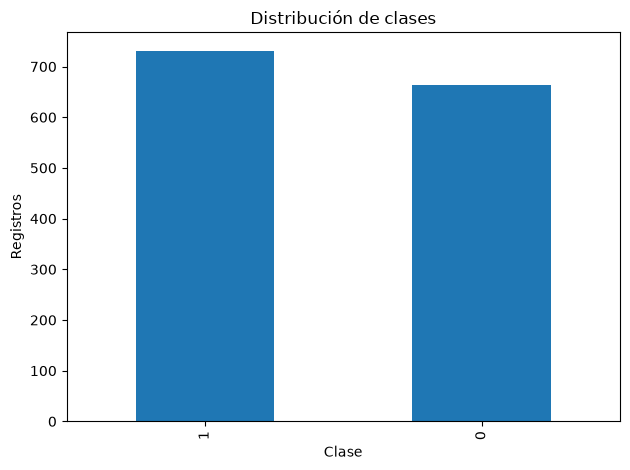

In [3]:
display(df[spec.target].value_counts(dropna=False).rename('registros').to_frame())
print('Filas duplicadas:', result['full_row_duplicates'])
print('Filas con texto repetido:', result['text_duplicates'])
print('Textos con etiquetas conflictivas:', result['conflicting_normalized_texts'])
df[spec.target].astype(str).value_counts().plot(kind='bar', title='Distribución de clases')
plt.xlabel('Clase'); plt.ylabel('Registros'); plt.tight_layout(); plt.show()

## Longitud, idioma y patrones

,caracteres,palabras
count,1395.000000,1395.000000
min,17.000000,2.000000
q25,505.000000,72.500000
median,759.000000,111.000000
mean,1255.001434,190.217204
q75,1317.500000,198.000000
p95,3731.500000,590.900000
max,28673.000000,3384.000000


Idiomas declarados o estimados: {'es': 1350, 'indeterminado': 25, 'en': 20}
Filas con URL/correo/teléfono: 411 334 601


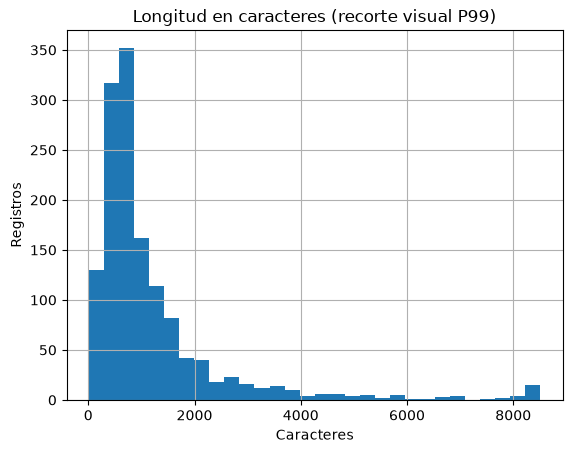

In [4]:
display(pd.DataFrame({
    'caracteres': result['length_characters'],
    'palabras': result['length_words'],
}))
print('Idiomas declarados o estimados:', result['declared_languages'] or result['language_heuristic'])
print('Filas con URL/correo/teléfono:', result['rows_with_url_pattern'], result['rows_with_email_pattern'], result['rows_with_phone_pattern'])
text = combined_text(df, spec.text_columns)
text.str.len().clip(upper=text.str.len().quantile(.99)).hist(bins=30)
plt.title('Longitud en caracteres (recorte visual P99)'); plt.xlabel('Caracteres'); plt.ylabel('Registros'); plt.show()

## Ejemplos sanitizados y conclusión

In [5]:
for label, examples in result['examples'].items():
    print(f'\nClase {label}')
    for example in examples:
        print('-', example)


Clase 0
- Registro_Beneficiarios_Plataforma_SNI REGISTRO DE BENEFICIARIOS EN CASO DE FALLECIMIENTO A los investigadores de nuevo ingreso y reingreso no-vigente cuya vigencia inició el 1º de enero del 2025, se hace de su conocimiento que pueden realizar el registro de sus beneficiarios en l…
- MyOwn Mario Castillo Buen día Dr. Lázaro, un gusto saludarle, no sé si me recuerde, soy Mario Castillo de MyOwn, tomé materia de la Maestría en Ciberseguridad con Usted, le comento que actualmente sigo en MyOwn, y estoy realizando trámites para el ingreso a Doctorado aquí en MyOw…

Clase 1
- Ezequiela Miguelina - Tienes (1) paquete esperando ser entregado 📦. Usa tu código para rastrearlo y recibirlo ___🚚. ID#41868 ❒ ENTREGA DEL PAQUETE PENDIENTE ◉ Registro / Inicio de sesión ❒ Correos [telefono-oculto] SEGUIMIENTO ➢ pablito Tienes (1) paquete pendiente de entrega ---…
- >>Ezequiela Miguelina!! - Hai un (1) pacco in attesa di consegna 📦. Usa il tuo codice per tracciarlo e riceverlo ___🚚. ENTREGA D

La interpretación, riesgos de fuga, sesgos, utilidad para Random Forest y estrategia de combinación están documentados en [`../reports/spanish_phishing.md`](../reports/spanish_phishing.md).